# Weeks 2–3 – Dataset Validation and Exploratory Analysis

**Status:** Handbook dataset-validation and EDA scope complete  
**Data coverage:** January 2024 through September 2026  
**Reporting checkpoint:** October 10, 2026

This notebook combines reproducible aggregate analysis with written interpretation. Reusable implementation remains in `src/weeks2_3_validate.py`; no row-level MLS records are displayed.

## Objective and handbook checklist

This chapter documents:

- Rows, columns, data types, and 33-month coverage
- Pre-filter property types and the exact Residential filter
- Market-analysis fields versus identifiers and metadata
- Null counts, percentages, and columns above 90% missing
- Retain/review/exclude recommendations without deleting source fields
- Histograms, boxplots, and percentiles for all nine requested numeric fields
- Median and average prices and DaysOnMarket distributions
- Sold-above, at, and below-list shares
- Counties with the highest median close prices
- Repeated-identifier counts
- Preliminary aggregate date-consistency findings

The separate mortgage-rate requirement is documented in `02_03_mortgage_enrichment.ipynb`.

## Confidentiality rules

Only aggregate output is allowed. Do not display raw MLS DataFrames or output identifiers, addresses, names, coordinates, or contact fields. The tables and plots below summarize groups or numeric distributions only.

## 1. Environment and reusable imports

In [1]:
from pathlib import Path
import gc
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.weeks2_3_validate import (
    EXPECTED_ROWS,
    INPUT_FILES,
    NUMERIC_FIELDS,
    analyze_date_consistency,
    analyze_field_roles,
    analyze_filtered_categories,
    analyze_identifier_repetition,
    analyze_missing_values,
    analyze_numeric_distributions,
    analyze_sold_market_questions,
    inspect_structure,
    validate_inputs,
)

sns.set_theme(style="whitegrid")

## 2. Coverage and filtering

The source audit found eight property types before filtering. Residential represents 63.60% of listing records and 67.25% of sold records. The exact filter is:

```python
frame["PropertyType"] == "Residential"
```

The resulting processed datasets contain only Residential records.

In [2]:
validate_inputs()

coverage = pd.DataFrame(
    [
        {
            "dataset": dataset,
            "expected_rows": EXPECTED_ROWS[dataset],
            "file_size_mb": round(path.stat().st_size / (1024**2), 1),
            "file_exists": path.exists(),
        }
        for dataset, path in INPUT_FILES.items()
    ]
)

coverage

INPUT FILES
listings: data/processed/combined_listings_residential.csv (302.6 MB)
sold: data/processed/combined_sold_residential.csv (281.7 MB)


,dataset,expected_rows,file_size_mb,file_exists
0,listings,655943,302.6,True
1,sold,495334,281.7,True


### Coverage finding

- Listings: 655,943 Residential records, 75 columns, and 33 source months.
- Sold: 495,334 Residential records, 86 columns, and 33 source months.
- Both datasets cover January 2024 through September 2026.
- Neither processed dataset contains a non-Residential record.

## 3. Aggregate-only visualization helpers

For readable charts, the visualized distributions are capped at the 1st and 99th percentiles. The complete minimum, maximum, and percentile values remain in the numeric summary, so extreme values are still documented rather than silently discarded.

In [3]:
def plot_missingness(
    report: pd.DataFrame,
    title: str,
    limit: int = 15,
) -> None:
    plot_data = (
        report.loc[report["missing_percent"] > 0]
        .head(limit)
        .sort_values("missing_percent")
    )

    ax = plot_data.plot.barh(
        x="column",
        y="missing_percent",
        legend=False,
        figsize=(9, 6),
        color="#4C78A8",
    )
    ax.axvline(90, color="#E45756", linestyle="--", label="90% threshold")
    ax.set_title(title)
    ax.set_xlabel("Missing values (%)")
    ax.set_ylabel("")
    ax.legend()
    plt.tight_layout()
    plt.show()


def plot_numeric_review(
    frame: pd.DataFrame,
    fields: list[str],
    dataset_label: str,
) -> pd.DataFrame:
    cap_rows = []
    histogram_figure, histogram_axes = plt.subplots(
        3,
        3,
        figsize=(16, 13),
    )
    boxplot_figure, boxplot_axes = plt.subplots(
        3,
        3,
        figsize=(16, 13),
    )

    for column, histogram_axis, boxplot_axis in zip(
        fields,
        histogram_axes.flat,
        boxplot_axes.flat,
    ):
        values = pd.to_numeric(frame[column], errors="coerce").dropna()
        lower = values.quantile(0.01)
        upper = values.quantile(0.99)
        central = values.loc[values.between(lower, upper)]

        cap_rows.append(
            {
                "column": column,
                "valid_values": len(values),
                "plot_minimum_1st_percentile": lower,
                "plot_maximum_99th_percentile": upper,
                "tail_values_not_plotted": len(values) - len(central),
            }
        )

        sns.histplot(
            central,
            bins=40,
            ax=histogram_axis,
            color="#59A14F",
        )
        histogram_axis.set_title(column)
        histogram_axis.set_ylabel("Record count")

        sns.boxplot(
            x=central,
            ax=boxplot_axis,
            color="#F28E2B",
        )
        boxplot_axis.set_title(column)
        boxplot_axis.set_xlabel("")

    histogram_figure.suptitle(
        f"{dataset_label}: numeric histograms, central 98%",
        fontsize=16,
    )
    histogram_figure.tight_layout()
    plt.show()

    boxplot_figure.suptitle(
        f"{dataset_label}: numeric boxplots, central 98%",
        fontsize=16,
    )
    boxplot_figure.tight_layout()
    plt.show()

    return pd.DataFrame(cap_rows)

## 4. Listings analysis

In [4]:
listings = inspect_structure(
    dataset="listings",
    path=INPUT_FILES["listings"],
)
listings_missing = analyze_missing_values(
    frame=listings,
    dataset="listings",
)
listings_numeric = analyze_numeric_distributions(
    frame=listings,
    dataset="listings",
)
listings_roles = analyze_field_roles(
    frame=listings,
    dataset="listings",
)
listings_categories = analyze_filtered_categories(
    frame=listings,
    dataset="listings",
)
listings_identifiers = analyze_identifier_repetition(
    frame=listings,
    dataset="listings",
)
listings_dates = analyze_date_consistency(
    frame=listings,
    dataset="listings",
)

display(
    listings_missing.head(15).reset_index(drop=True)
)
display(listings_numeric)
display(listings_roles)
display(listings_identifiers)
display(listings_dates)


Loading listings...
Rows: 655,943
Columns: 75
Source months: 33
Non-Residential rows: 0
Data types:
  str: 39 columns
  float64: 29 columns
  int64: 4 columns
  object: 3 columns

LISTINGS MISSING VALUES
Columns with missing values: 63 of 75
Columns above 90% missing: 13
Ten highest missing percentages:
  TaxAnnualAmount: 655,943 missing (100.00%)
  AboveGradeFinishedArea: 655,943 missing (100.00%)
  FireplacesTotal: 655,943 missing (100.00%)
  TaxYear: 655,943 missing (100.00%)
  ElementarySchoolDistrict: 655,943 missing (100.00%)
  BusinessType: 655,943 missing (100.00%)
  CoveredSpaces: 655,943 missing (100.00%)
  MiddleOrJuniorSchoolDistrict: 655,943 missing (100.00%)
  BelowGradeFinishedArea: 652,071 missing (99.41%)
  CoBuyerAgentFirstName: 637,257 missing (97.15%)
Columns above 90% missing:
  TaxAnnualAmount: 100.00%
  AboveGradeFinishedArea: 100.00%
  FireplacesTotal: 100.00%
  TaxYear: 100.00%
  ElementarySchoolDistrict: 100.00%
  BusinessType: 100.00%
  CoveredSpaces: 100.00

,column,missing_count,missing_percent,recommendation
0,TaxAnnualAmount,655943,100.000000,exclude_current_analysis_all_missing
1,AboveGradeFinishedArea,655943,100.000000,exclude_current_analysis_all_missing
2,FireplacesTotal,655943,100.000000,exclude_current_analysis_all_missing
3,TaxYear,655943,100.000000,exclude_current_analysis_all_missing
4,ElementarySchoolDistrict,655943,100.000000,exclude_current_analysis_all_missing
5,BusinessType,655943,100.000000,exclude_current_analysis_all_missing
6,CoveredSpaces,655943,100.000000,exclude_current_analysis_all_missing
7,MiddleOrJuniorSchoolDistrict,655943,100.000000,exclude_current_analysis_all_missing
8,BelowGradeFinishedArea,652071,99.409705,review_sparse_exclude_by_default
9,CoBuyerAgentFirstName,637257,97.151277,review_sparse_exclude_by_default


,column,valid_count,missing_percent,minimum,percentile_25,median,mean,percentile_75,percentile_99,maximum,coercion_failures
0,ClosePrice,186708,71.535941,360.0,599990.0000,850000.00,1.200770e+06,1.350000e+06,5.574510e+06,8.200000e+08,0
1,ListPrice,655943,0.000000,0.0,579900.0000,840000.00,1.308346e+06,1.374900e+06,8.000000e+06,4.000000e+08,0
2,OriginalListPrice,655002,0.143458,0.0,585000.0000,849000.00,1.390882e+06,1.388000e+06,8.498000e+06,1.749000e+09,0
3,LivingArea,655302,0.097722,0.0,1248.0000,1671.00,1.973715e+03,2.300000e+03,6.266990e+03,1.702132e+07,0
4,LotSizeAcres,603043,8.064725,0.0,0.1203,0.17,5.978617e+01,3.173000e-01,1.349950e+01,4.187292e+06,0
5,BedroomsTotal,655765,0.027137,0.0,2.0000,3.00,3.228054e+00,4.000000e+00,6.000000e+00,9.400000e+01,0
6,BathroomsTotalInteger,655887,0.008537,0.0,2.0000,2.00,2.626992e+00,3.000000e+00,7.000000e+00,2.208000e+03,0
7,DaysOnMarket,655943,0.000000,-75.0,5.0000,11.00,2.048284e+01,2.400000e+01,1.410000e+02,1.155000e+03,0
8,YearBuilt,654842,0.167850,1776.0,1961.0000,1980.00,1.979674e+03,2.001000e+03,2.026000e+03,2.028000e+03,0


,field_role,present_count,missing_count,present_fields,missing_fields
0,identifiers,3,0,"ListingKey, ListingKeyNumeric, ListingId",
1,dates,4,0,"ListingContractDate, PurchaseContractDate, Clo...",
2,prices,4,0,"ListPrice, OriginalListPrice, ClosePrice, Asso...",
3,property_characteristics,9,0,"PropertyType, PropertySubType, LivingArea, Lot...",
4,geography,6,0,"CountyOrParish, City, PostalCode, MLSAreaMajor...",
5,market_participants,7,0,"ListOfficeName, BuyerOfficeName, ListAgentFull...",
6,other_metadata,42,0,"ListAgentEmail, UnparsedAddress, CoListOfficeN...",


,identifier,nonmissing_records,unique_identifiers,repeated_identifier_values,records_using_repeated_identifiers
0,ListingKey,655943,655742,199,400
1,ListingKeyNumeric,655943,655742,199,400
2,ListingId,655943,655719,222,446


,check,eligible_records,violation_count,violation_percent
0,listing_after_purchase,325710,320,0.098247
1,purchase_after_close,210168,264,0.125614
2,listing_after_close,210199,88,0.041865


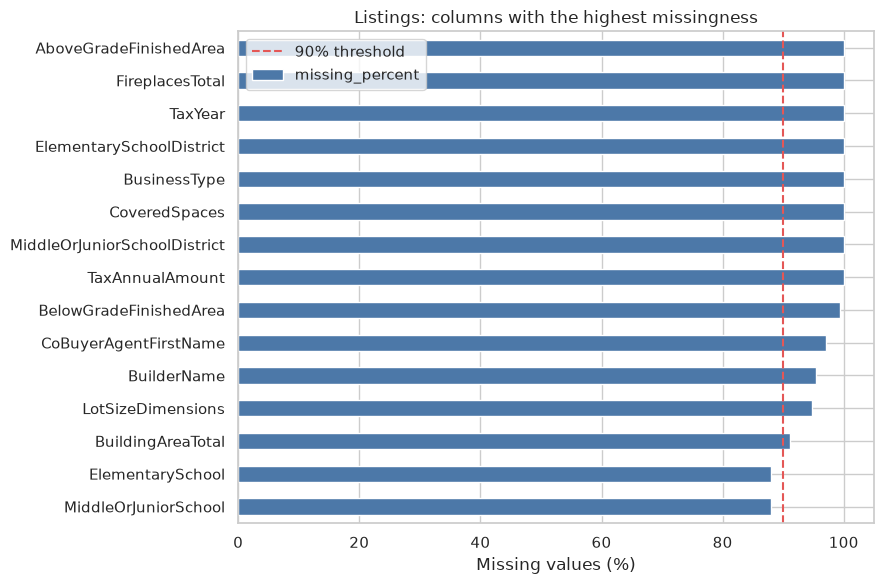

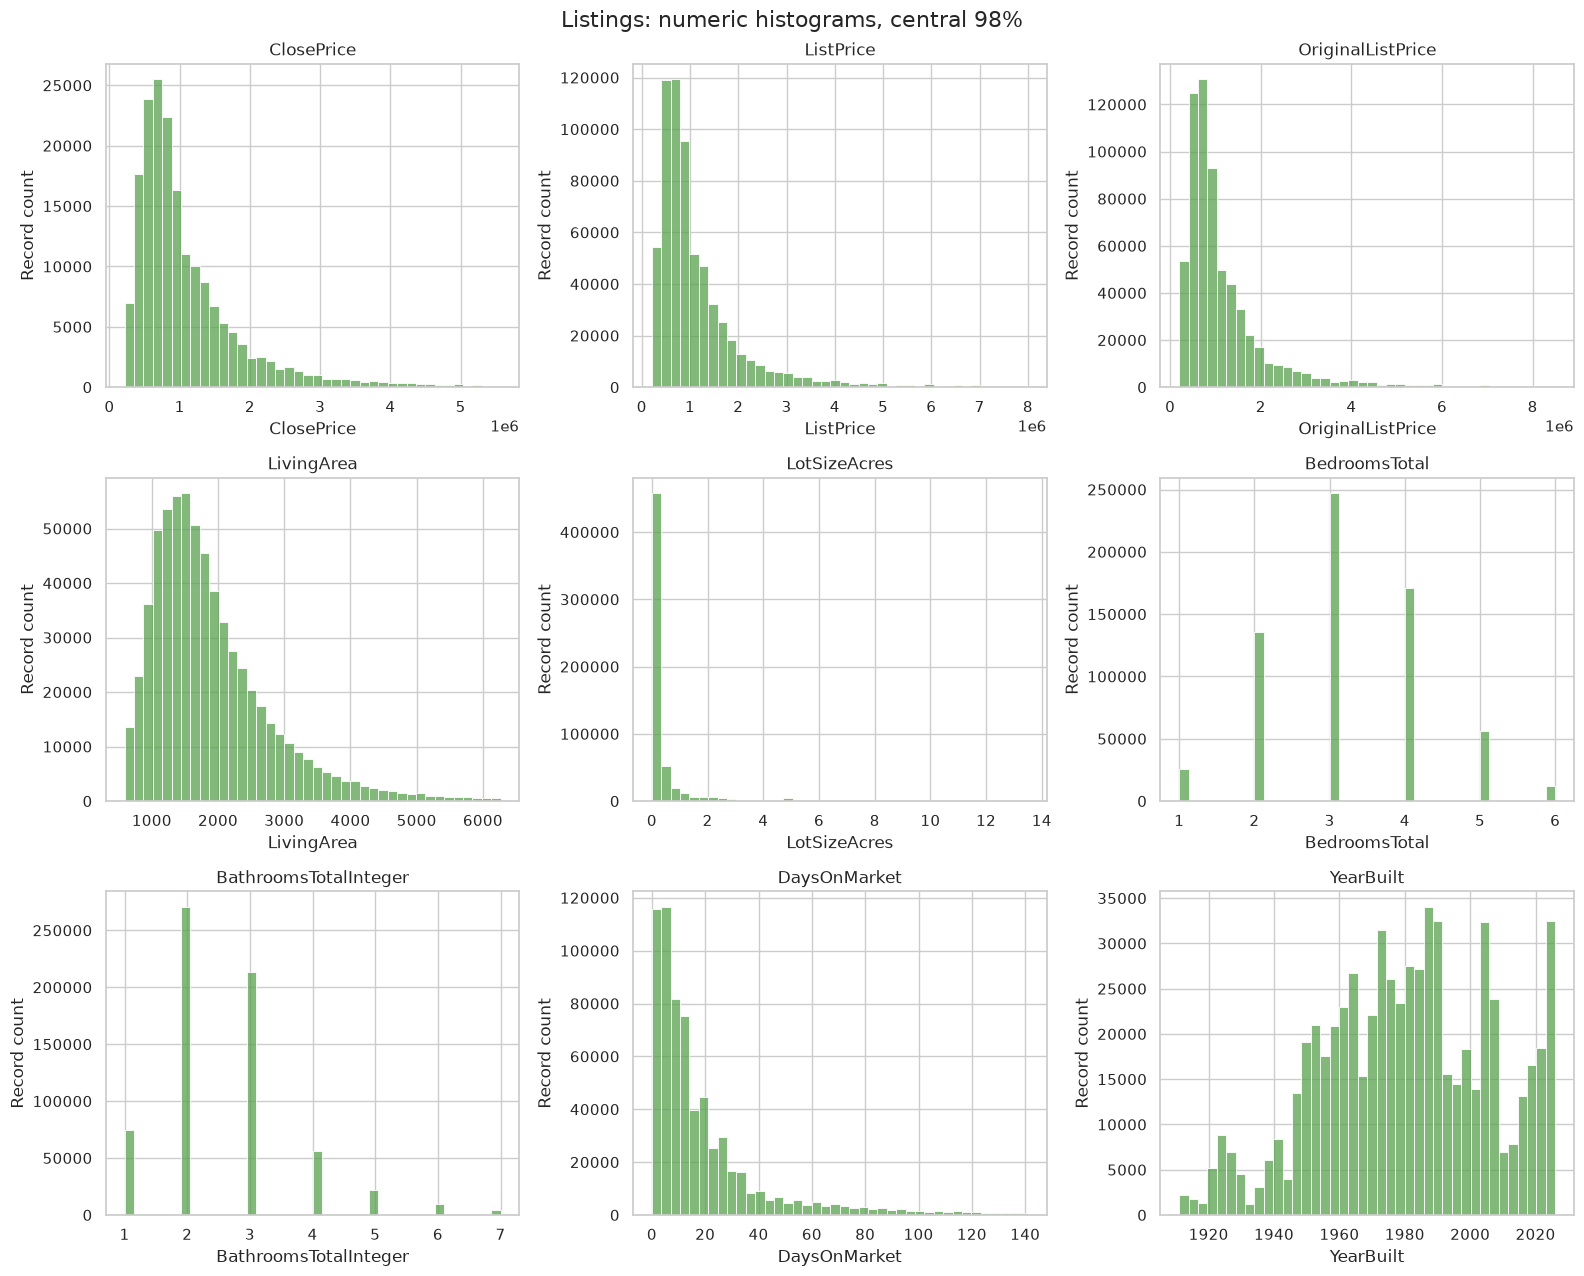

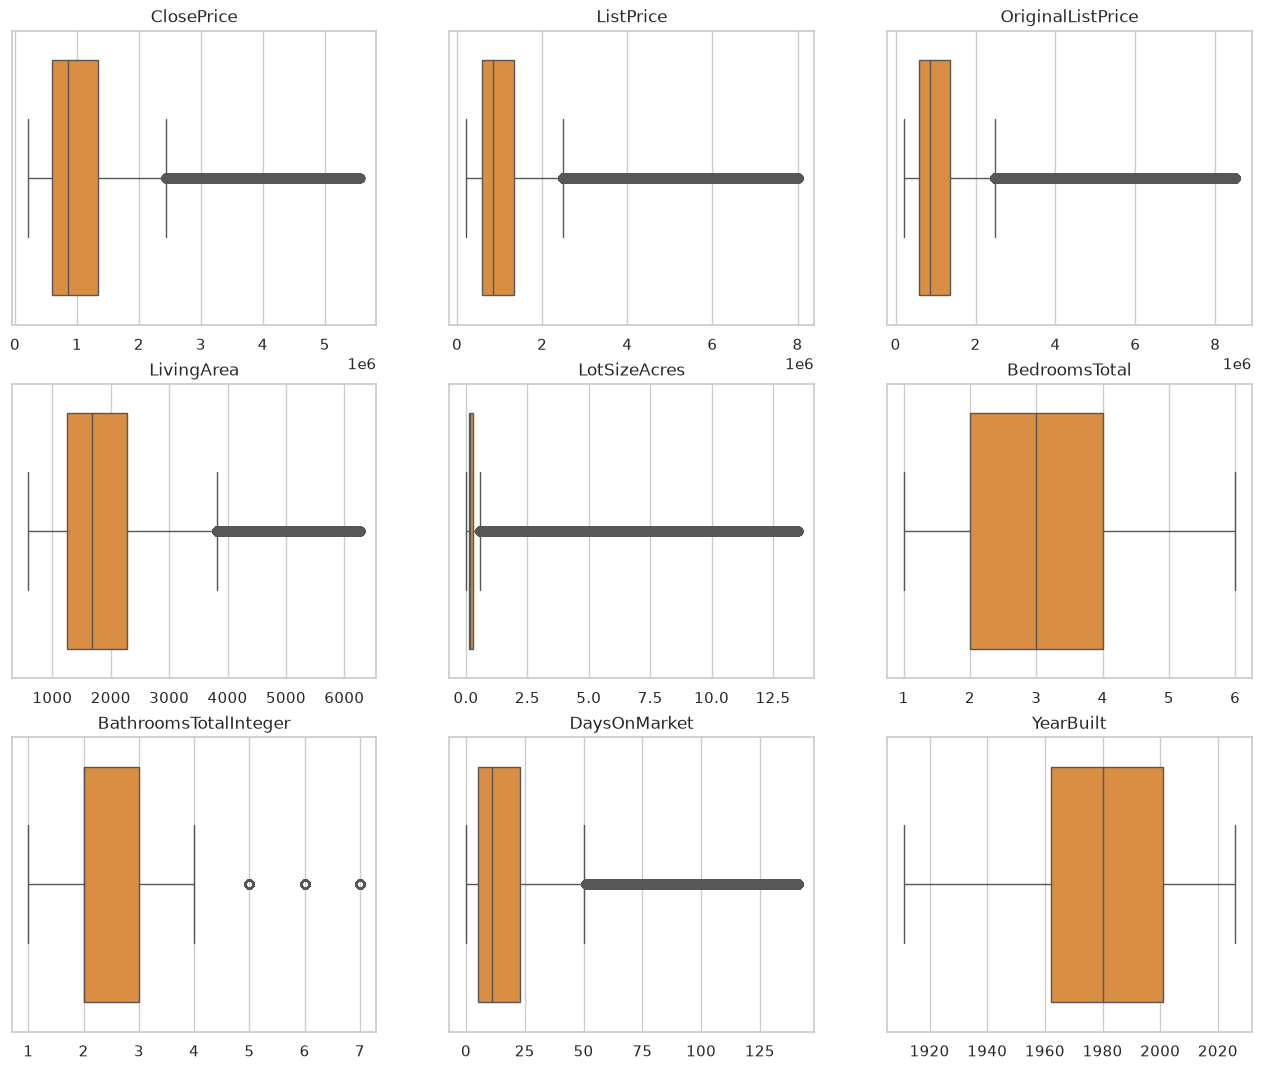

,column,valid_values,plot_minimum_1st_percentile,plot_maximum_99th_percentile,tail_values_not_plotted
0,ClosePrice,186708,215000.0,5.574510e+06,3718
1,ListPrice,655943,210000.0,8.000000e+06,13002
2,OriginalListPrice,655002,200000.0,8.498000e+06,13016
3,LivingArea,655302,588.0,6.266990e+03,13053
4,LotSizeAcres,603043,0.0,1.349950e+01,6029
5,BedroomsTotal,655765,1.0,6.000000e+00,7870
6,BathroomsTotalInteger,655887,1.0,7.000000e+00,5209
7,DaysOnMarket,655943,0.0,1.410000e+02,6439
8,YearBuilt,654842,1911.0,2.026000e+03,6168


In [5]:
plot_missingness(
    listings_missing,
    "Listings: columns with the highest missingness",
)
listings_plot_ranges = plot_numeric_review(
    frame=listings,
    fields=NUMERIC_FIELDS["listings"],
    dataset_label="Listings",
)
display(listings_plot_ranges)

### Listings findings

- 63 of 75 columns contain missing values; 13 exceed 90% missing.
- Eight fields are completely empty and are excluded from current analysis while preserved in source data.
- Median ListPrice is $840,000; median LivingArea is 1,671 square feet; median DaysOnMarket is 11.
- Single Family Residence represents 72.99% of filtered listing records, followed by Condominium at 17.98% and Townhouse at 5.87%.
- ListingKey has 199 repeated values across 400 records. These are flagged for later record-level review.
- Preliminary date checks found 320 listing-after-purchase, 264 purchase-after-close, and 88 listing-after-close cases among eligible records.
- ClosePrice is 71.54% missing, consistent with a listings-side population containing records that did not become closed sales.
- Negative DaysOnMarket and extreme price, area, acreage, bedroom, bathroom, and future YearBuilt values remain documented for cleaning and outlier phases.

In [6]:
del listings
gc.collect()

970

## 5. Sold analysis

The listings DataFrame is released before loading sold data to control memory use.

In [7]:
sold = inspect_structure(
    dataset="sold",
    path=INPUT_FILES["sold"],
)
sold_missing = analyze_missing_values(
    frame=sold,
    dataset="sold",
)
sold_numeric = analyze_numeric_distributions(
    frame=sold,
    dataset="sold",
)
sold_roles = analyze_field_roles(
    frame=sold,
    dataset="sold",
)
sold_categories = analyze_filtered_categories(
    frame=sold,
    dataset="sold",
)
sold_identifiers = analyze_identifier_repetition(
    frame=sold,
    dataset="sold",
)
sold_dates = analyze_date_consistency(
    frame=sold,
    dataset="sold",
)
sold_price_outcomes, sold_counties = analyze_sold_market_questions(sold)

display(sold_missing.head(15).reset_index(drop=True))
display(sold_numeric)
display(sold_roles)
display(sold_identifiers)
display(sold_dates)
display(sold_price_outcomes)
display(sold_counties)


Loading sold...
Rows: 495,334
Columns: 86
Source months: 33
Non-Residential rows: 0
Data types:
  str: 44 columns
  float64: 29 columns
  object: 9 columns
  int64: 4 columns

SOLD MISSING VALUES
Columns with missing values: 74 of 86
Columns above 90% missing: 15
Ten highest missing percentages:
  CoveredSpaces: 495,334 missing (100.00%)
  MiddleOrJuniorSchoolDistrict: 495,334 missing (100.00%)
  TaxYear: 495,334 missing (100.00%)
  TaxAnnualAmount: 495,334 missing (100.00%)
  AboveGradeFinishedArea: 495,334 missing (100.00%)
  FireplacesTotal: 495,334 missing (100.00%)
  ElementarySchoolDistrict: 495,334 missing (100.00%)
  BusinessType: 495,334 missing (100.00%)
  WaterfrontYN: 495,023 missing (99.94%)
  BelowGradeFinishedArea: 492,318 missing (99.39%)
Columns above 90% missing:
  CoveredSpaces: 100.00%
  MiddleOrJuniorSchoolDistrict: 100.00%
  TaxYear: 100.00%
  TaxAnnualAmount: 100.00%
  AboveGradeFinishedArea: 100.00%
  FireplacesTotal: 100.00%
  ElementarySchoolDistrict: 100.00%

,column,missing_count,missing_percent,recommendation
0,CoveredSpaces,495334,100.000000,exclude_current_analysis_all_missing
1,MiddleOrJuniorSchoolDistrict,495334,100.000000,exclude_current_analysis_all_missing
2,TaxYear,495334,100.000000,exclude_current_analysis_all_missing
3,TaxAnnualAmount,495334,100.000000,exclude_current_analysis_all_missing
4,AboveGradeFinishedArea,495334,100.000000,exclude_current_analysis_all_missing
5,FireplacesTotal,495334,100.000000,exclude_current_analysis_all_missing
6,ElementarySchoolDistrict,495334,100.000000,exclude_current_analysis_all_missing
7,BusinessType,495334,100.000000,exclude_current_analysis_all_missing
8,WaterfrontYN,495023,99.937214,review_sparse_exclude_by_default
9,BelowGradeFinishedArea,492318,99.391118,review_sparse_exclude_by_default


,column,valid_count,missing_percent,minimum,percentile_25,median,mean,percentile_75,percentile_99,maximum,coercion_failures
0,ClosePrice,495332,0.000404,0.0,575000.0000,825000.000,1.188512e+06,1.300000e+06,5.600000e+06,9.895000e+08,0
1,ListPrice,495334,0.000000,1.0,575000.0000,819000.000,1.144931e+06,1.295000e+06,5.795000e+06,1.700000e+08,0
2,OriginalListPrice,494431,0.182301,0.0,585000.0000,829000.000,1.227853e+06,1.299000e+06,5.995000e+06,1.390000e+09,0
3,LivingArea,495060,0.055316,0.0,1250.0000,1648.000,1.902627e+03,2.227000e+03,5.300000e+03,1.702132e+07,0
4,LotSizeAcres,457347,7.668967,0.0,0.1202,0.167,5.830052e+01,2.755000e-01,1.098853e+01,7.810698e+06,0
5,BedroomsTotal,495321,0.002624,0.0,3.0000,3.000,3.208053e+00,4.000000e+00,6.000000e+00,4.500000e+01,0
6,BathroomsTotalInteger,495263,0.014334,0.0,2.0000,2.000,2.540874e+00,3.000000e+00,6.000000e+00,1.750000e+02,0
7,DaysOnMarket,495334,0.000000,-288.0,8.0000,19.000,3.764360e+01,4.900000e+01,2.350000e+02,1.243000e+04,0
8,YearBuilt,494891,0.089435,1776.0,1960.0000,1979.000,1.978684e+03,1.999000e+03,2.025000e+03,2.027000e+03,0


,field_role,present_count,missing_count,present_fields,missing_fields
0,identifiers,3,0,"ListingKey, ListingKeyNumeric, ListingId",
1,dates,4,0,"ListingContractDate, PurchaseContractDate, Clo...",
2,prices,4,0,"ListPrice, OriginalListPrice, ClosePrice, Asso...",
3,property_characteristics,9,0,"PropertyType, PropertySubType, LivingArea, Lot...",
4,geography,6,0,"CountyOrParish, City, PostalCode, MLSAreaMajor...",
5,market_participants,7,0,"ListOfficeName, BuyerOfficeName, ListAgentFull...",
6,other_metadata,53,0,"Flooring, ViewYN, WaterfrontYN, BasementYN, Po...",


,identifier,nonmissing_records,unique_identifiers,repeated_identifier_values,records_using_repeated_identifiers
0,ListingKey,495334,494954,376,756
1,ListingKeyNumeric,495334,494954,376,756
2,ListingId,495334,494952,378,760


,check,eligible_records,violation_count,violation_percent
0,listing_after_purchase,495136,316,0.063821
1,purchase_after_close,495137,243,0.049077
2,listing_after_close,495333,75,0.015141


,outcome,record_count,share_percent
0,sold_above_list,196249,39.619769
1,sold_at_list,86408,17.444497
2,sold_below_list,212674,42.935734


,county,transaction_count,median_close_price,mean_close_price
0,San Mateo,8457,1700000.0,2.194863e+06
1,Santa Clara,21069,1590000.0,1.919824e+06
2,San Francisco,1129,1200000.0,1.354707e+06
3,Santa Cruz,3558,1188500.0,1.347264e+06
4,Orange,55787,1185000.0,1.551276e+06
5,Marin,173,1170000.0,1.361201e+06
6,Alameda,23436,1130000.0,1.304925e+06
7,Monterey,4728,910000.0,1.398759e+06
8,Los Angeles,123099,905000.0,1.330103e+06
9,San Diego,61665,900000.0,1.449357e+06


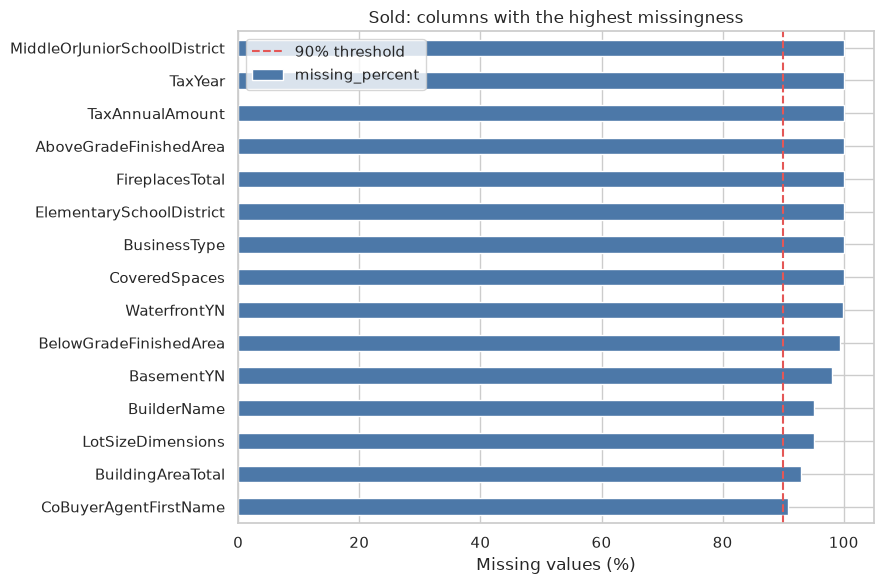

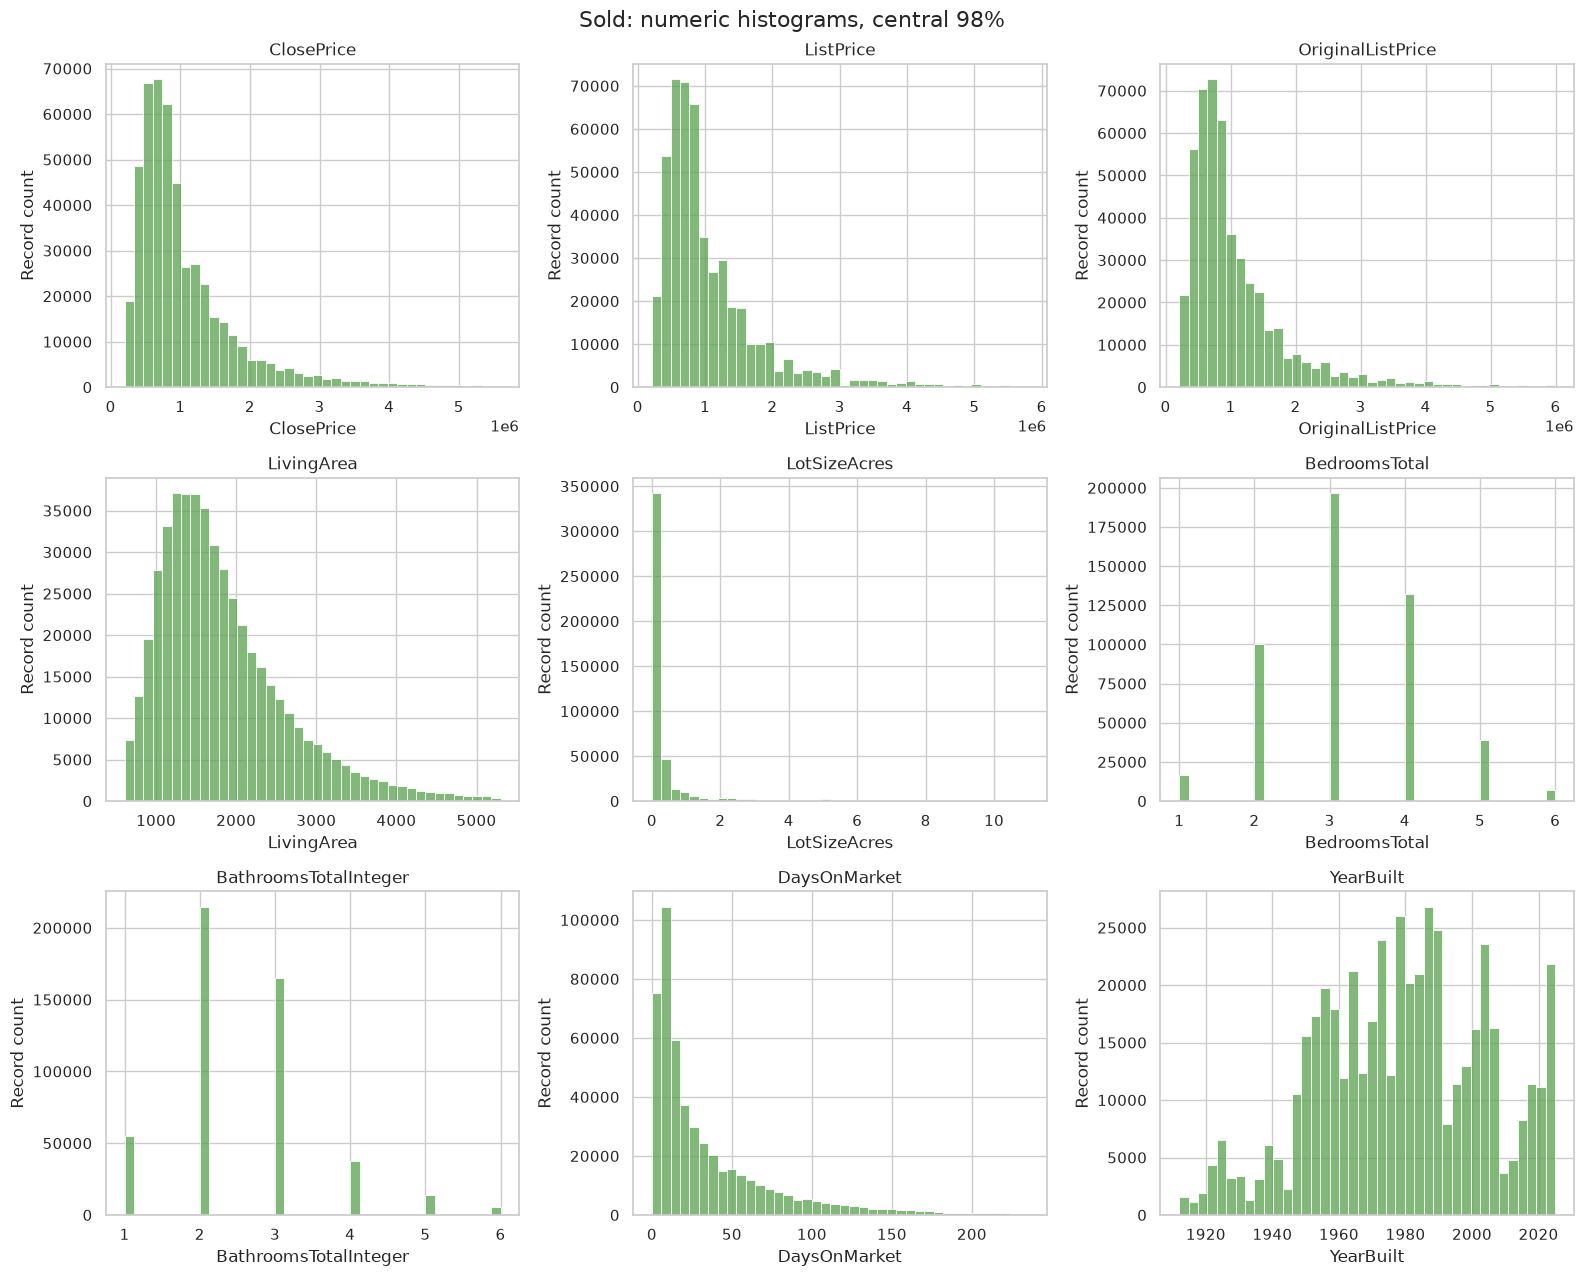

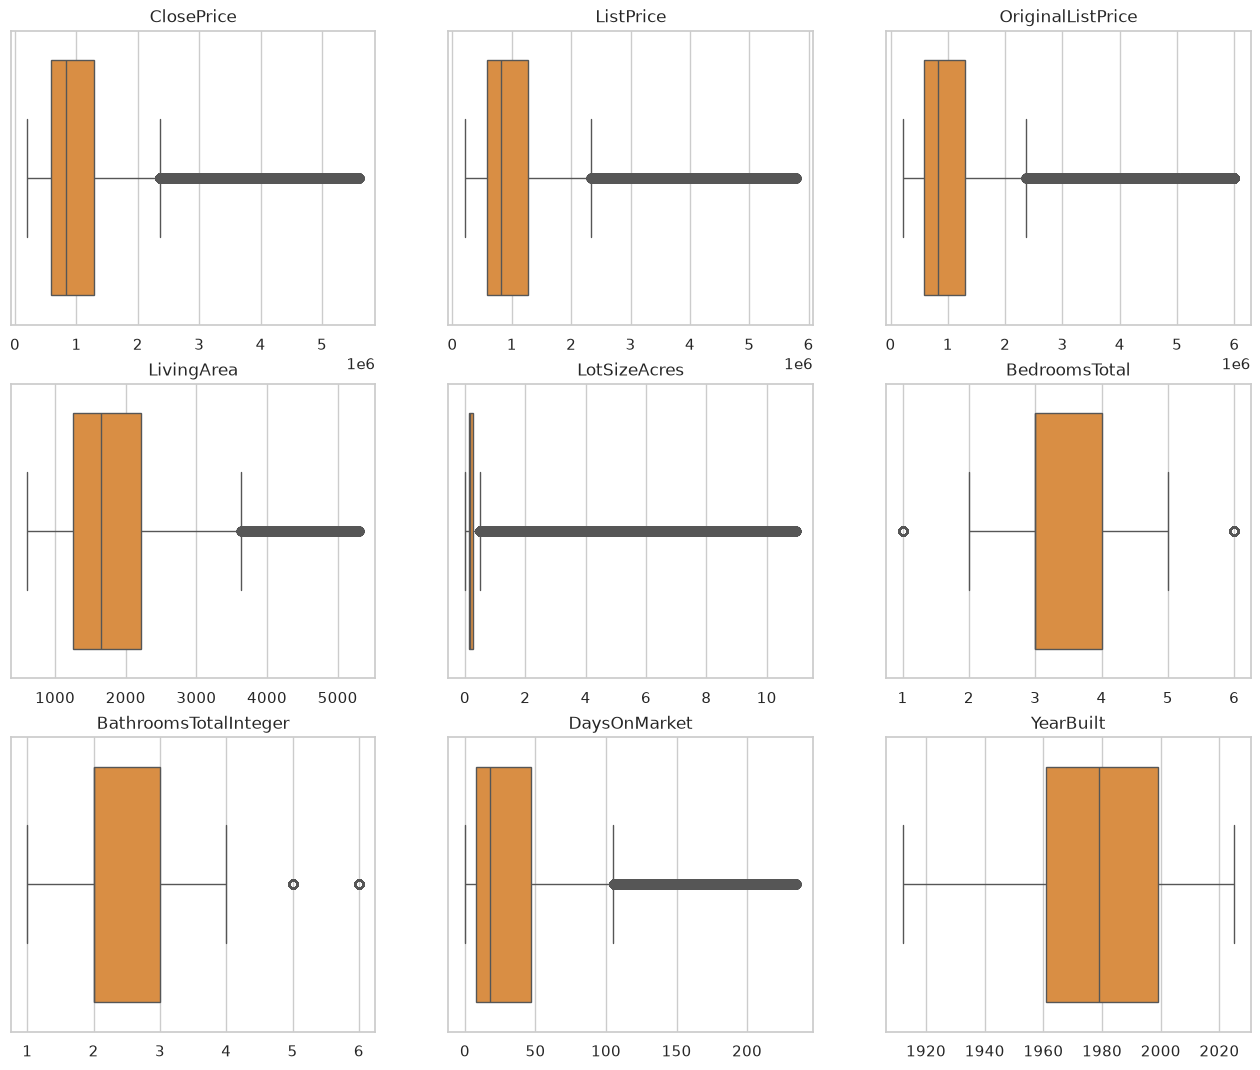

,column,valid_values,plot_minimum_1st_percentile,plot_maximum_99th_percentile,tail_values_not_plotted
0,ClosePrice,495332,200000.0,5.600000e+06,9617
1,ListPrice,495334,210000.0,5.795000e+06,9769
2,OriginalListPrice,494431,210000.0,5.995000e+06,9740
3,LivingArea,495060,606.0,5.300000e+03,9884
4,LotSizeAcres,457347,0.0,1.098853e+01,4574
5,BedroomsTotal,495321,1.0,6.000000e+00,3591
6,BathroomsTotalInteger,495263,1.0,6.000000e+00,3863
7,DaysOnMarket,495334,0.0,2.350000e+02,4950
8,YearBuilt,494891,1912.0,2.025000e+03,7546


In [8]:
plot_missingness(
    sold_missing,
    "Sold: columns with the highest missingness",
)
sold_plot_ranges = plot_numeric_review(
    frame=sold,
    fields=NUMERIC_FIELDS["sold"],
    dataset_label="Sold",
)
display(sold_plot_ranges)

### Sold findings

- 74 of 86 columns contain missing values; 15 exceed 90% missing.
- Median ClosePrice is $825,000; median LivingArea is 1,648 square feet; median DaysOnMarket is 19.
- Single Family Residence represents 74.95% of filtered sold records.
- Only two sold records lack ClosePrice.
- Among valid positive ClosePrice/ListPrice comparisons, 39.62% sold above list, 17.44% at list, and 42.94% below list.
- The highest median ClosePrice among counties with at least 100 records is San Mateo at $1.70 million, followed by Santa Clara at $1.59 million.
- ListingKey has 376 repeated values across 756 records.
- Preliminary date checks found 316 listing-after-purchase, 243 purchase-after-close, and 75 listing-after-close cases among eligible sold records.
- Extreme numeric values remain flagged for the formal cleaning and outlier phases.

## 6. Central-value comparison and complete observed ranges

In [9]:
def statistic(
    report: pd.DataFrame,
    field: str,
    measure: str,
) -> float:
    return report.set_index("column").loc[field, measure]


central_comparison = pd.DataFrame(
    {
        "measure": [
            "Relevant price median",
            "LivingArea median",
            "DaysOnMarket median",
            "DaysOnMarket mean",
        ],
        "listings": [
            statistic(listings_numeric, "ListPrice", "median"),
            statistic(listings_numeric, "LivingArea", "median"),
            statistic(listings_numeric, "DaysOnMarket", "median"),
            statistic(listings_numeric, "DaysOnMarket", "mean"),
        ],
        "sold": [
            statistic(sold_numeric, "ClosePrice", "median"),
            statistic(sold_numeric, "LivingArea", "median"),
            statistic(sold_numeric, "DaysOnMarket", "median"),
            statistic(sold_numeric, "DaysOnMarket", "mean"),
        ],
    }
)

central_comparison

,measure,listings,sold
0,Relevant price median,840000.000000,825000.000000
1,LivingArea median,1671.000000,1648.000000
2,DaysOnMarket median,11.000000,19.000000
3,DaysOnMarket mean,20.482841,37.643602


In [10]:
range_rows = []
for dataset, report in (
    ("listings", listings_numeric),
    ("sold", sold_numeric),
):
    indexed = report.set_index("column")
    for field in NUMERIC_FIELDS[dataset]:
        range_rows.append(
            {
                "dataset": dataset,
                "field": field,
                "minimum": indexed.loc[field, "minimum"],
                "maximum": indexed.loc[field, "maximum"],
                "percentile_99": indexed.loc[field, "percentile_99"],
            }
        )

observed_ranges = pd.DataFrame(range_rows)
observed_ranges

,dataset,field,minimum,maximum,percentile_99
0,listings,ClosePrice,360.0,8.200000e+08,5.574510e+06
1,listings,ListPrice,0.0,4.000000e+08,8.000000e+06
2,listings,OriginalListPrice,0.0,1.749000e+09,8.498000e+06
3,listings,LivingArea,0.0,1.702132e+07,6.266990e+03
4,listings,LotSizeAcres,0.0,4.187292e+06,1.349950e+01
5,listings,BedroomsTotal,0.0,9.400000e+01,6.000000e+00
6,listings,BathroomsTotalInteger,0.0,2.208000e+03,7.000000e+00
7,listings,DaysOnMarket,-75.0,1.155000e+03,1.410000e+02
8,listings,YearBuilt,1776.0,2.028000e+03,2.026000e+03
9,sold,ClosePrice,0.0,9.895000e+08,5.600000e+06


In [11]:
del sold
gc.collect()

60346

## 7. Decisions and assumptions

- Structural validation passed for both September-inclusive datasets.
- All-missing fields are excluded from current analysis but preserved in source files.
- Fields above 90% missing are reviewed and excluded by default unless a business question requires them.
- Core fields are retained even when partially missing.
- Extreme values are flagged before exclusion; nothing is silently deleted.
- Medians and percentiles are preferred for early descriptions because the distributions are highly skewed.
- Listings-side and sold-side metrics remain conceptually separate.
- Current results describe records, not confirmed unique properties or unique transactions.
- The formal row-level date and validity flags will be created during Weeks 4–5, as directed by the handbook.

## 8. Questions carried into cleaning

1. Which repeated ListingKey cases represent legitimate updates versus duplicate records?
2. Are negative DaysOnMarket values ever legitimate under CRMLS business rules?
3. Should future YearBuilt values be retained as planned/new construction?
4. Which sparse fields are needed for later Tableau or competitive-analysis requirements?
5. What minimum transaction count should be required for published geographic comparisons?

## 9. Completion checklist

- [x] Rows, columns, types, and coverage
- [x] Pre-filter property types and Residential shares
- [x] Exact filtering logic
- [x] Null counts and percentages
- [x] Columns above 90% null
- [x] Retain/review/exclude recommendations
- [x] Percentiles for all nine numeric fields
- [x] Histograms for all nine numeric fields
- [x] Boxplots for all nine numeric fields
- [x] Price and DaysOnMarket questions
- [x] County median-price summary
- [x] Preliminary date consistency
- [x] Filtered datasets saved privately

**Next chapter:** `02_03_mortgage_enrichment.ipynb`

## References

- Validation and EDA code: `src/weeks2_3_validate.py`
- Aggregation and pre-filter category code: `src/week1_aggregate.py`
- Mortgage enrichment code: `src/weeks2_3_mortgage.py`
- Final phase summary: `reports/weeks2_3_final_report.md`
- Chronological notes: `docs/project_log.md`